 OOB error convergence; max_features comparison; manual bootstrap bagging; permutation importance; rf_vs_single_tree() function

=== Single Tree vs Random Forest Comparison ===
Single Decision Tree Validation Accuracy: 0.4667
Random Forest Validation Accuracy       : 0.5333



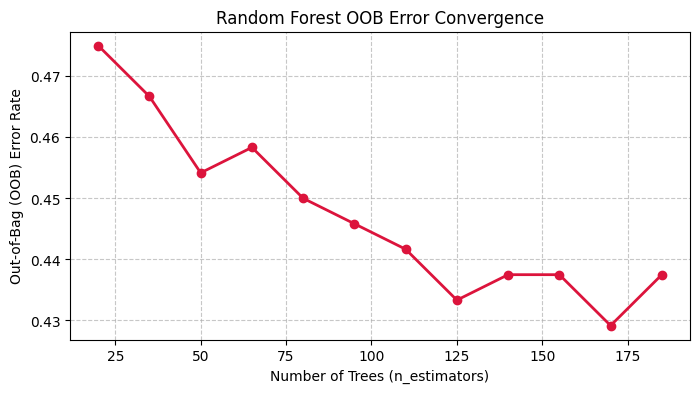

=== max_features Comparison DataFrame ===
  max_features  val_accuracy
0         sqrt      0.533333
1         log2      0.533333
2          0.5      0.550000
3          1.0      0.600000


Manual Bootstrap Bagging (50 trees) Validation Accuracy: 0.5500



/tmp/ipykernel_672/1519736984.py:167: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


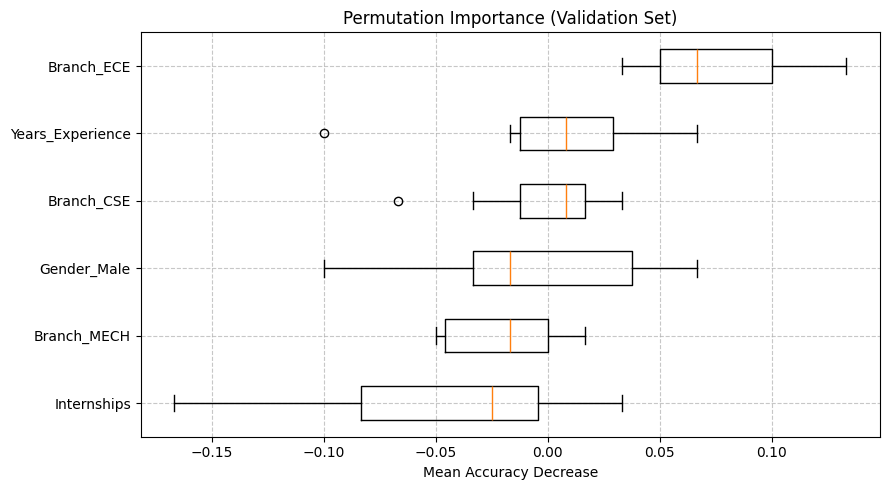

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 1. Setup Dataset, Preprocessor, and Integer-Casted Targets
np.random.seed(42)
n_samples = 300

data = {
    'Branch': np.random.choice(['CSE', 'ECE', 'MECH', 'CIVIL'], n_samples),
    'Gender': np.random.choice(['Male', 'Female'], n_samples),
    'Years_Experience': np.random.uniform(0, 3, n_samples),
    'Internships': np.random.randint(0, 4, n_samples),
    'PlacementStatus': np.random.choice([0, 1], n_samples, p=[0.4, 0.6]),
}
df = pd.DataFrame(data)

X = df.drop(columns=['PlacementStatus'])
# Ensure target labels are strictly integers
y_binary = df['PlacementStatus'].astype(int)

categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()
numerical_cols = X.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore', drop='first'),
            categorical_cols,
        ),
    ]
)

X_train, X_val, y_train, y_val = train_test_split(
    X, y_binary, test_size=0.2, random_state=42
)

# Transform data
preprocessed_X_train = preprocessor.fit_transform(X_train)
preprocessed_X_val = preprocessor.transform(X_val)


# 2. rf_vs_single_tree() Function & Execution
def rf_vs_single_tree(X_tr, y_tr, X_v, y_v):
  """Trains and compares a Single Decision Tree vs a Random Forest Classifier."""
  dt = DecisionTreeClassifier(random_state=42)
  dt.fit(X_tr, y_tr)
  dt_acc = accuracy_score(y_v, dt.predict(X_v))

  rf = RandomForestClassifier(random_state=42)
  rf.fit(X_tr, y_tr)
  rf_acc = accuracy_score(y_v, rf.predict(X_v))

  print('=== Single Tree vs Random Forest Comparison ===')
  print(f'Single Decision Tree Validation Accuracy: {dt_acc:.4f}')
  print(f'Random Forest Validation Accuracy       : {rf_acc:.4f}')
  print('=' * 49 + '\n')
  return dt, rf


dt_model, rf_model = rf_vs_single_tree(
    preprocessed_X_train, y_train, preprocessed_X_val, y_val
)


# 3. OOB Error Convergence
error_rates = []
estimator_range = range(20, 200, 15)

for n in estimator_range:
  rf_oob = RandomForestClassifier(
      n_estimators=n, oob_score=True, random_state=42
  )
  rf_oob.fit(preprocessed_X_train, y_train)
  error_rates.append(1 - rf_oob.oob_score_)

plt.figure(figsize=(8, 4))
plt.plot(
    list(estimator_range), error_rates, marker='o', color='crimson', lw=2
)
plt.xlabel('Number of Trees (n_estimators)')
plt.ylabel('Out-of-Bag (OOB) Error Rate')
plt.title('Random Forest OOB Error Convergence')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# 4. max_features Comparison (Using integer-casted targets)
max_features_options = ['sqrt', 'log2', 0.5, 1.0]
mf_results = []

for mf in max_features_options:
  rf_mf = RandomForestClassifier(max_features=mf, random_state=42)
  rf_mf.fit(preprocessed_X_train, y_train)
  acc = accuracy_score(y_val, rf_mf.predict(preprocessed_X_val))
  mf_results.append({'max_features': str(mf), 'val_accuracy': acc})

mf_df = pd.DataFrame(mf_results)
print('=== max_features Comparison DataFrame ===')
print(mf_df)
print('\n')


# 5. Manual Bootstrap Bagging Implementation
def manual_bootstrap_bagging(X_tr, y_tr, X_v, y_v, n_trees=50):
  """Builds a manual bagging ensemble using bootstrap samples and majority voting."""
  n_samples = X_tr.shape[0]
  trees = []

  for _ in range(n_trees):
    indices = np.random.choice(n_samples, size=n_samples, replace=True)
    X_boot, y_boot = X_tr[indices], y_tr.to_numpy()[indices]

    tree = DecisionTreeClassifier(random_state=None)
    tree.fit(X_boot, y_boot)
    trees.append(tree)

  preds = np.array([tree.predict(X_v) for tree in trees])
  final_preds = np.apply_along_axis(
      lambda x: np.bincount(x).argmax(), axis=0, arr=preds
  )

  bagging_acc = accuracy_score(y_v, final_preds)
  print(
      f'Manual Bootstrap Bagging ({n_trees} trees) Validation Accuracy:'
      f' {bagging_acc:.4f}\n'
  )
  return bagging_acc


manual_bootstrap_bagging(
    preprocessed_X_train, y_train, preprocessed_X_val, y_val, n_trees=50
)


# 6. Permutation Importance
rf_final = RandomForestClassifier(random_state=42)
rf_final.fit(preprocessed_X_train, y_train)

result = permutation_importance(
    rf_final, preprocessed_X_val, y_val, n_repeats=10, random_state=42
)
sorted_idx = result.importances_mean.argsort()

cat_feature_names = (
    preprocessor.named_transformers_['cat']
    .get_feature_names_out(categorical_cols)
    .tolist()
)
feature_names_list = numerical_cols + cat_feature_names

plt.figure(figsize=(9, 5))
plt.boxplot(
    result.importances[sorted_idx].T,
    vert=False,
    labels=np.array(feature_names_list)[sorted_idx],
)
plt.title('Permutation Importance (Validation Set)')
plt.xlabel('Mean Accuracy Decrease')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Write rf_vs_single_tree(X_train, y_train, X_val, y_val, n_estimators_list) — returns DataFrame [n_estimators, RF_val_acc, DT_val_acc,
OOB_acc], plots 3 lines

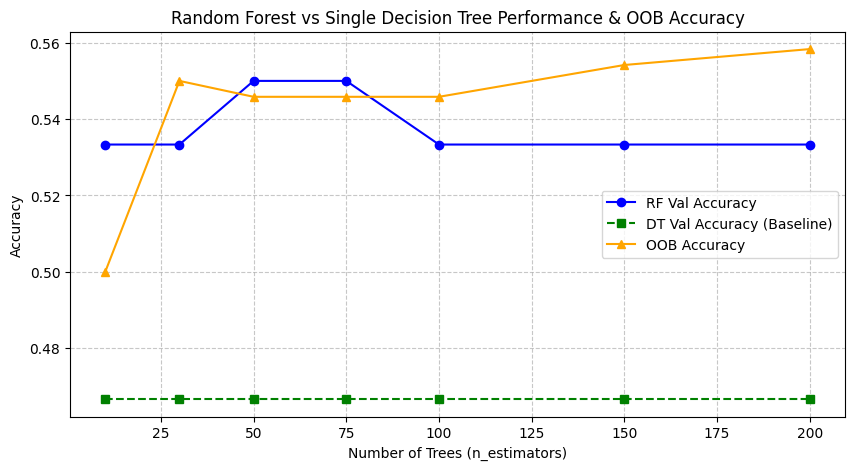

   n_estimators  RF_val_acc  DT_val_acc   OOB_acc
0            10    0.533333    0.466667  0.500000
1            30    0.533333    0.466667  0.550000
2            50    0.550000    0.466667  0.545833
3            75    0.550000    0.466667  0.545833
4           100    0.533333    0.466667  0.545833
5           150    0.533333    0.466667  0.554167
6           200    0.533333    0.466667  0.558333


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier


def rf_vs_single_tree(X_train, y_train, X_val, y_val, n_estimators_list):
  """Trains a Single Decision Tree and evaluates Random Forest across a list of n_estimators.

  Returns a DataFrame: [n_estimators, RF_val_acc, DT_val_acc, OOB_acc] and plots
  curves.
  """
  results = []

  # 1. Train Single Decision Tree once (baseline for comparison)
  dt = DecisionTreeClassifier(random_state=42)
  dt.fit(X_train, y_train)
  dt_val_acc = accuracy_score(y_val, dt.predict(X_val))

  # 2. Iterate through each n_estimators value for Random Forest
  for n in n_estimators_list:
    # Random Forest with OOB score enabled
    rf = RandomForestClassifier(
        n_estimators=n, oob_score=True, random_state=42
    )
    rf.fit(X_train, y_train)

    rf_val_acc = accuracy_score(y_val, rf.predict(X_val))
    oob_acc = (
        rf.oob_score_
    )  # OOB accuracy is 1 - OOB error (or directly oob_score_)

    results.append({
        'n_estimators': n,
        'RF_val_acc': rf_val_acc,
        'DT_val_acc': dt_val_acc,  # Stored for direct row-by-row comparison
        'OOB_acc': oob_acc,
    })

  # Create DataFrame
  df_results = pd.DataFrame(results)

  # 3. Plot the 3 lines
  plt.figure(figsize=(10, 5))
  plt.plot(
      df_results['n_estimators'],
      df_results['RF_val_acc'],
      marker='o',
      label='RF Val Accuracy',
      color='blue',
  )
  plt.plot(
      df_results['n_estimators'],
      df_results['DT_val_acc'],
      marker='s',
      linestyle='--',
      label='DT Val Accuracy (Baseline)',
      color='green',
  )
  plt.plot(
      df_results['n_estimators'],
      df_results['OOB_acc'],
      marker='^',
      label='OOB Accuracy',
      color='orange',
  )

  plt.xlabel('Number of Trees (n_estimators)')
  plt.ylabel('Accuracy')
  plt.title('Random Forest vs Single Decision Tree Performance & OOB Accuracy')
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.7)
  plt.show()

  return df_results


# --- Example Execution ---
estimators_range = [10, 30, 50, 75, 100, 150, 200]
comparison_summary_df = rf_vs_single_tree(
    preprocessed_X_train, y_train, preprocessed_X_val, y_val, estimators_range
)
print(comparison_summary_df)